# Подготовка данных

Цель ноутбука — проверить качество Banking77, исключить пересечения
между обучающей и тестовой выборками и сохранить фиксированные
`train`, `validation` и `test`.

Официальный `test` не используется для выбора моделей.

*Первое сравнение моделей. Новый эксперимент с отдельной выборкой для выбора порога и замером скорости находится в `06_routing_and_latency.ipynb`; его метрики хранятся отдельно в `reports/portfolio`.*

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split


RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

raw_train = pd.read_csv(RAW_DIR / "train.csv")
raw_test = pd.read_csv(RAW_DIR / "test.csv")

pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(raw_train), len(raw_test)],
    "classes": [
        raw_train["category"].nunique(),
        raw_test["category"].nunique(),
    ],
})

,split,rows,classes
0,train,10003,77
1,test,3080,77


## Краткий аудит

Проверяем пропуски, дубликаты, баланс классов и совпадение набора
категорий между официальными разбиениями.

In [4]:
audit = pd.DataFrame({
    "train": {
        "missing_values": raw_train.isna().sum().sum(),
        "full_duplicates": raw_train.duplicated().sum(),
        "duplicate_texts": raw_train["text"].duplicated().sum(),
    },
    "test": {
        "missing_values": raw_test.isna().sum().sum(),
        "full_duplicates": raw_test.duplicated().sum(),
        "duplicate_texts": raw_test["text"].duplicated().sum(),
    },
}).T

class_counts = raw_train["category"].value_counts()

display(audit)
display(class_counts.describe().to_frame("objects_per_class"))

print(
    "Классы только в train:",
    set(raw_train["category"]) - set(raw_test["category"]),
)
print(
    "Классы только в test:",
    set(raw_test["category"]) - set(raw_train["category"]),
)

,missing_values,full_duplicates,duplicate_texts
train,0,0,0
test,0,0,0


,objects_per_class
count,77.000000
mean,129.909091
std,32.942207
min,35.000000
25%,112.000000
50%,127.000000
75%,159.000000
max,187.000000


Классы только в train: set()
Классы только в test: set()


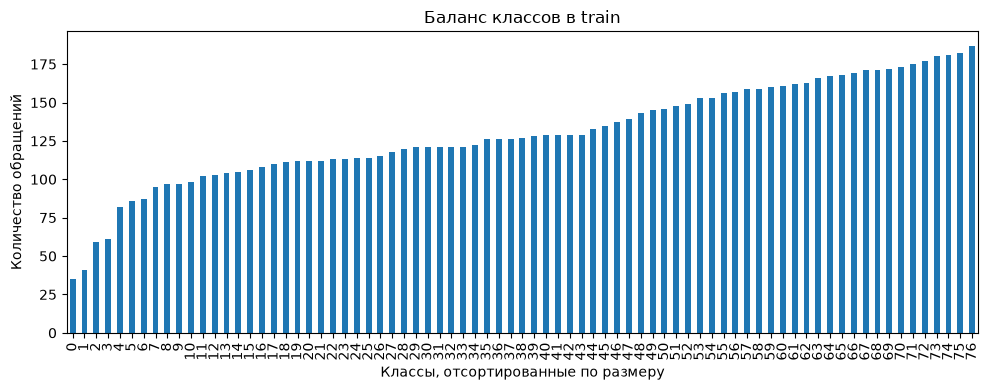

In [5]:
class_counts.sort_values().reset_index(drop=True).plot(
    kind="bar",
    figsize=(10, 4),
    legend=False,
)

plt.xlabel("Классы, отсортированные по размеру")
plt.ylabel("Количество обращений")
plt.title("Баланс классов в train")
plt.tight_layout()
plt.show()

## Удаление пересечений с test

Текст нормализуется только для поиска совпадений. Сам исходный текст
не изменяется. Совпадающие обращения удаляются только из train,
официальный test остаётся неизменным.

In [6]:
def normalize_text(text: str) -> str:
    return " ".join(text.lower().split())


train_clean = raw_train.drop_duplicates(
    subset=["text", "category"]
).copy()

train_clean["_text_normalized"] = (
    train_clean["text"].map(normalize_text)
)
test_normalized = raw_test["text"].map(normalize_text)

overlap_mask = train_clean["_text_normalized"].isin(
    set(test_normalized)
)
overlap_count = int(overlap_mask.sum())

overlap_info = (
    train_clean.loc[
        overlap_mask,
        ["_text_normalized", "category"],
    ]
    .merge(
        raw_test.assign(
            _text_normalized=test_normalized
        )[["_text_normalized", "category"]],
        on="_text_normalized",
        suffixes=("_train", "_test"),
    )
)

label_conflicts = (
    overlap_info["category_train"]
    != overlap_info["category_test"]
).sum()

train_clean = (
    train_clean.loc[
        ~overlap_mask,
        ["text", "category"],
    ]
    .reset_index(drop=True)
)

print("Пересечений train/test:", overlap_count)
print("Совпадений с разными метками:", int(label_conflicts))
print("Train после очистки:", train_clean.shape)

Пересечений train/test: 7
Совпадений с разными метками: 0
Train после очистки: (9996, 2)


## Фиксированное разбиение

Из очищенного train выделяется стратифицированная validation-выборка.
Все дальнейшие модели используют эти же файлы.

In [7]:
train_df, val_df = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=42,
    stratify=train_clean["category"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = raw_test[["text", "category"]].copy()

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(
    PROCESSED_DIR / "train.csv",
    index=False,
)
val_df.to_csv(
    PROCESSED_DIR / "validation.csv",
    index=False,
)
test_df.to_csv(
    PROCESSED_DIR / "test.csv",
    index=False,
)

pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [
        len(train_df),
        len(val_df),
        len(test_df),
    ],
    "classes": [
        train_df["category"].nunique(),
        val_df["category"].nunique(),
        test_df["category"].nunique(),
    ],
})

,split,rows,classes
0,train,7996,77
1,validation,2000,77
2,test,3080,77


## Результат

Подготовлены три фиксированных разбиения без пересечений между
обучающими данными и официальным test. Эти файлы используются во всех
последующих экспериментах.